# Credit Risk Assessment — XGBoost Model Training
## Objective
Train an **XGBoost** classifier to predict **loan default** (`loan_status = 1`) using the cleaned and preprocessed credit risk dataset produced in notebook `01_data_preprocessing_and_eda`.
### Workflow
1. Load & inspect the cleaned dataset
2. Exploratory review of class imbalance
3. Train / Validation / Test split
4. Feature scaling
5. Baseline XGBoost model
6. Hyperparameter tuning with cross-validation
7. Handle class imbalance with SMOTE
8. Evaluate the tuned model (Confusion Matrix, ROC-AUC, Precision-Recall)
9. Feature importance analysis
10. Save the final model & scaler artifacts
11. Track experiments & compare runs with MLflow


---
## 1 · Imports & Configuration

In [1]:
# Core
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Splitting
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler

# Imbalanced-learn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Model
import xgboost as xgb

# Evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    f1_score,
    accuracy_score
)

# Model persistence
import joblib
import os

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

# Experiment Tracking
import mlflow
import mlflow.xgboost

# Configure MLflow Experiment
EXPERIMENT_NAME = 'Credit_Risk_Loan_Default_Prediction'
mlflow.set_experiment(EXPERIMENT_NAME)

print('All libraries loaded successfully.')


2026/10/11 00:00:20 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/11 00:00:20 INFO mlflow.store.db.utils: Updating database tables
2026/10/11 00:00:22 INFO mlflow.tracking.fluent: Experiment with name 'Credit_Risk_Loan_Default_Prediction' does not exist. Creating a new experiment.


All libraries loaded successfully.


---
## 2 · Load & Inspect Cleaned Data

In [2]:
DATA_PATH = '../data/processed/credit_risk_cleaned.csv'
df = pd.read_csv(DATA_PATH)

print(f'Dataset shape: {df.shape}')
print(f'Missing values: {df.isnull().sum().sum()}')
df.head()

Dataset shape: (32409, 18)
Missing values: 0


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length,loan_grade_enc,cb_default_enc,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,21,9600,5.0,1000,11.14,0,0.10,2,2,0,0,1,0,1,0,0,0,0
1,25,9600,1.0,5500,12.87,1,0.57,3,3,0,0,0,0,0,0,1,0,0
2,23,65500,4.0,35000,15.23,1,0.53,2,3,0,0,0,1,0,0,1,0,0
3,24,54400,8.0,35000,14.27,1,0.55,4,3,1,0,0,1,0,0,1,0,0
4,21,9900,2.0,2500,7.14,1,0.25,2,1,0,0,1,0,0,0,0,0,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32409 entries, 0 to 32408
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   person_age                   32409 non-null  int64  
 1   person_income                32409 non-null  int64  
 2   person_emp_length            32409 non-null  float64
 3   loan_amnt                    32409 non-null  int64  
 4   loan_int_rate                32409 non-null  float64
 5   loan_status                  32409 non-null  int64  
 6   loan_percent_income          32409 non-null  float64
 7   cb_person_cred_hist_length   32409 non-null  int64  
 8   loan_grade_enc               32409 non-null  int64  
 9   cb_default_enc               32409 non-null  int64  
 10  person_home_ownership_OTHER  32409 non-null  int64  
 11  person_home_ownership_OWN    32409 non-null  int64  
 12  person_home_ownership_RENT   32409 non-null  int64  
 13  loan_intent_EDUC

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,32409.0,27.730754,6.210445,20.00,23.00,26.00,30.00,94.00
person_income,32409.0,64859.414453,40362.590262,4000.00,38500.00,55000.00,79200.00,300000.00
person_emp_length,32409.0,4.761424,3.983757,0.00,2.00,4.00,7.00,41.00
loan_amnt,32409.0,9592.486655,6320.885127,500.00,5000.00,8000.00,12250.00,35000.00
loan_int_rate,32409.0,11.020010,3.213459,5.42,7.88,10.99,13.48,23.22
loan_status,32409.0,0.218705,0.413374,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32409.0,0.170248,0.106785,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32409.0,5.811194,4.057899,2.00,3.00,4.00,8.00,30.00
loan_grade_enc,32409.0,2.220463,1.167340,1.00,1.00,2.00,3.00,7.00
cb_default_enc,32409.0,0.176772,0.381481,0.00,0.00,0.00,0.00,1.00


### Analysis
The cleaned dataset contains **32,409 rows** and **18 columns** with zero missing values. Categorical features have already been one-hot encoded and ordinal features label-encoded during preprocessing in notebook 01.

---
## 3 · Class Imbalance Analysis

In [5]:
target_counts = df['loan_status'].value_counts()
target_pct = df['loan_status'].value_counts(normalize=True) * 100

print('Target distribution:')
print(target_counts)
print(f'\nClass 0 (No Default): {target_pct[0]:.1f}%')
print(f'Class 1 (Default):    {target_pct[1]:.1f}%')
print(f'Imbalance ratio:      {target_counts[0] / target_counts[1]:.2f}:1')

Target distribution:
loan_status
0    25321
1     7088
Name: count, dtype: int64

Class 0 (No Default): 78.1%
Class 1 (Default):    21.9%
Imbalance ratio:      3.57:1


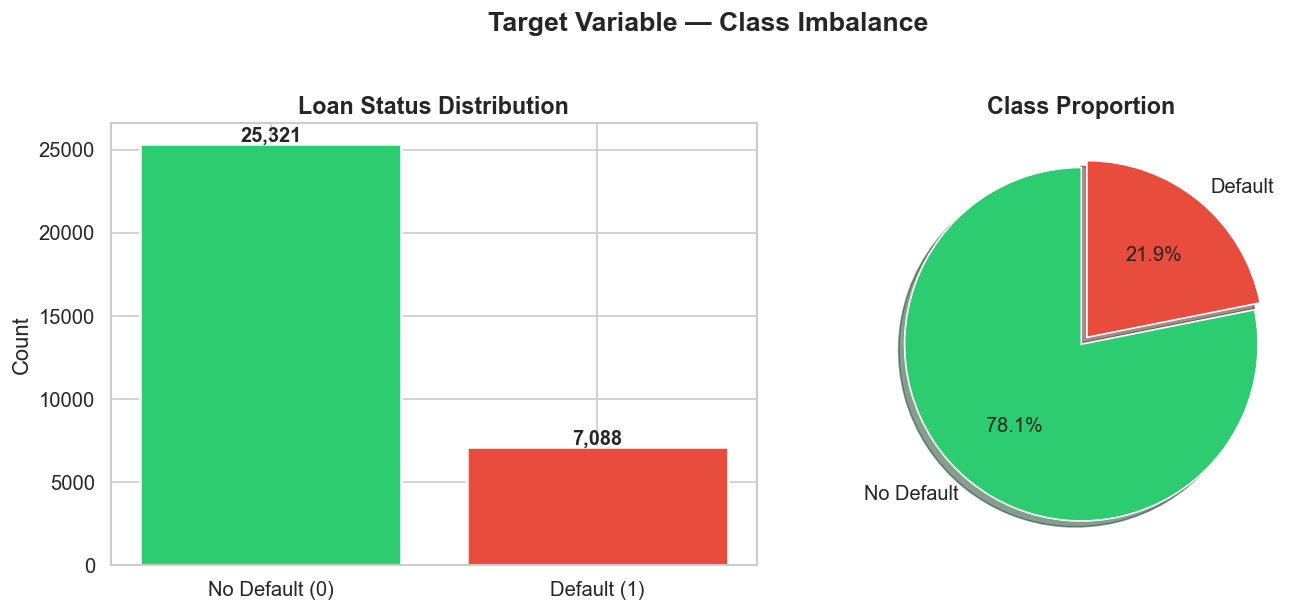

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
colors = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(['No Default (0)', 'Default (1)'], target_counts.values, color=colors, edgecolor='white', linewidth=1.5)
for bar, count in zip(bars, target_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'{count:,}', ha='center', fontweight='bold', fontsize=12)
axes[0].set_title('Loan Status Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count')

# Pie chart
axes[1].pie(target_counts.values, labels=['No Default', 'Default'],
            autopct='%1.1f%%', colors=colors, startangle=90,
            explode=(0, 0.05), shadow=True, textprops={'fontsize': 12})
axes[1].set_title('Class Proportion', fontsize=14, fontweight='bold')

plt.suptitle('Target Variable — Class Imbalance', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Analysis
The dataset is **imbalanced** with roughly a **3.6:1** ratio of non-default to default loans. This means:
- A naïve "always predict no default" classifier would achieve ~78% accuracy — accuracy alone is misleading.
- We need to focus on **Recall** (catching defaults), **Precision**, **F1-Score**, and **PR-AUC** as primary metrics.
- We will apply **SMOTE** to oversample the minority class during training and also use the `scale_pos_weight` parameter in XGBoost.

---
## 4 · Feature / Target Split & Train-Validation-Test Split

In [7]:
TARGET = 'loan_status'

X = df.drop(columns=[TARGET])
y = df[TARGET]

FEATURE_NAMES = X.columns.tolist()
print(f'Features ({len(FEATURE_NAMES)}): {FEATURE_NAMES}')

Features (17): ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'loan_grade_enc', 'cb_default_enc', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE']


In [8]:
# 60% train, 20% validation, 20% test — stratified to preserve class distribution
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f'Training set:   {X_train.shape[0]:,} samples ({y_train.mean():.2%} default)')
print(f'Validation set: {X_val.shape[0]:,} samples ({y_val.mean():.2%} default)')
print(f'Test set:       {X_test.shape[0]:,} samples ({y_test.mean():.2%} default)')

Training set:   19,445 samples (21.87% default)
Validation set: 6,482 samples (21.88% default)
Test set:       6,482 samples (21.86% default)


### Analysis
Data is split **before** any fitting (scaling, SMOTE) to prevent data leakage. Stratification ensures each split mirrors the original class distribution (~21.9% default).

---
## 5 · Feature Scaling
XGBoost is tree-based and technically scale-invariant, but standardizing helps with convergence speed and is essential if we later compare against linear models. We fit the scaler on **training data only**.

In [9]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURE_NAMES, index=X_train.index)
X_val_scaled   = pd.DataFrame(scaler.transform(X_val),       columns=FEATURE_NAMES, index=X_val.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),      columns=FEATURE_NAMES, index=X_test.index)

print('Scaler fitted on training data and applied to all splits.')
X_train_scaled.head()

Scaler fitted on training data and applied to all splits.


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_grade_enc,cb_default_enc,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
3584,-0.760618,0.006777,-0.700597,-0.950147,0.142005,-1.033294,-0.937583,-0.191992,-0.466553,-0.057465,-0.293584,0.993797,-0.5,-0.355799,-0.473973,-0.452351,-0.460987
12887,-0.921820,0.255111,0.303391,0.384821,-1.100919,-0.096843,-0.937583,-1.047661,-0.466553,-0.057465,-0.293584,0.993797,2.0,-0.355799,-0.473973,-0.452351,-0.460987
22856,0.045388,-0.117390,0.052394,-1.124964,-1.100919,-1.220584,0.299645,-1.047661,-0.466553,-0.057465,-0.293584,-1.006242,-0.5,2.810572,-0.473973,-0.452351,-0.460987
19444,0.045388,-0.738226,-0.449600,0.130541,0.210366,1.214188,0.547091,-0.191992,-0.466553,-0.057465,3.406182,-1.006242,-0.5,-0.355799,-0.473973,-0.452351,2.169261
5747,-1.083021,-0.465008,-0.198603,-0.886577,1.328998,-0.752358,-0.690137,1.519346,2.143379,-0.057465,-0.293584,-1.006242,-0.5,-0.355799,-0.473973,-0.452351,2.169261


---
## 6 · Baseline XGBoost Model
Train a quick baseline with default hyperparameters to establish a performance floor.

In [10]:
# scale_pos_weight accounts for class imbalance
scale_pos_weight = target_counts[0] / target_counts[1]

baseline_model = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    scale_pos_weight=scale_pos_weight,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

baseline_model.fit(
    X_train_scaled, y_train,
    eval_set=[(X_train_scaled, y_train), (X_val_scaled, y_val)],
    verbose=False
)

print('Baseline model trained.')

Baseline model trained.


In [11]:
# Evaluate baseline on validation set
y_val_pred_baseline = baseline_model.predict(X_val_scaled)
y_val_proba_baseline = baseline_model.predict_proba(X_val_scaled)[:, 1]

baseline_metrics = {
    'val_accuracy': float(accuracy_score(y_val, y_val_pred_baseline)),
    'val_f1': float(f1_score(y_val, y_val_pred_baseline)),
    'val_roc_auc': float(roc_auc_score(y_val, y_val_proba_baseline)),
    'val_pr_auc': float(average_precision_score(y_val, y_val_proba_baseline))
}

print('=== Baseline XGBoost — Validation Set ===')
print(classification_report(y_val, y_val_pred_baseline, target_names=['No Default', 'Default']))
print(f"ROC-AUC: {baseline_metrics['val_roc_auc']:.4f}")
print(f"PR-AUC:  {baseline_metrics['val_pr_auc']:.4f}")

# --- MLflow Logging: Run 1 (Baseline XGBoost) ---
with mlflow.start_run(run_name='01_Baseline_XGBoost'):
    # Log baseline parameters
    mlflow.log_params({
        'model_name': 'Baseline_XGBoost',
        'n_estimators': 200,
        'learning_rate': 0.1,
        'max_depth': 6,
        'scale_pos_weight': float(scale_pos_weight),
        'sampling': 'None',
        'random_state': RANDOM_STATE
    })
    # Log validation metrics
    mlflow.log_metrics(baseline_metrics)
    # Log baseline model artifact
    mlflow.xgboost.log_model(baseline_model, artifact_path='baseline_model')
    print('Baseline model run logged to MLflow.')


=== Baseline XGBoost — Validation Set ===
              precision    recall  f1-score   support

  No Default       0.94      0.96      0.95      5064
     Default       0.84      0.80      0.82      1418

    accuracy                           0.92      6482
   macro avg       0.89      0.88      0.88      6482
weighted avg       0.92      0.92      0.92      6482

ROC-AUC: 0.9494
PR-AUC:  0.9062


2026/10/11 00:00:24 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Baseline model run logged to MLflow.


### Analysis
The baseline model gives us a starting point. Let's now attempt to improve it through hyperparameter tuning and SMOTE oversampling.

---
## 7 · Hyperparameter Tuning (RandomizedSearchCV)
We use randomized search with stratified k-fold cross-validation, optimizing for **F1-Score** since we care about both precision and recall on the minority class.

In [12]:
param_distributions = {
    'n_estimators':      [100, 200, 300, 500],
    'max_depth':         [3, 4, 5, 6, 7, 8],
    'learning_rate':     [0.01, 0.05, 0.1, 0.2],
    'subsample':         [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree':  [0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight':  [1, 3, 5, 7],
    'gamma':             [0, 0.1, 0.2, 0.3],
    'reg_alpha':         [0, 0.01, 0.1, 1],
    'reg_lambda':        [1, 1.5, 2, 3]
}

xgb_base = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=50,
    scoring='f1',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

print('Starting hyperparameter search (50 iterations * 5 folds = 250 fits)...')
random_search.fit(X_train_scaled, y_train)

print(f'\n Best F1 score (CV): {random_search.best_score_:.4f}')
print(f'Best parameters:')
for param, value in random_search.best_params_.items():
    print(f'  {param}: {value}')

Starting hyperparameter search (50 iterations * 5 folds = 250 fits)...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

 Best F1 score (CV): 0.8166
Best parameters:
  subsample: 1.0
  reg_lambda: 3
  reg_alpha: 0.01
  n_estimators: 500
  min_child_weight: 3
  max_depth: 8
  learning_rate: 0.05
  gamma: 0.2
  colsample_bytree: 0.8


### Analysis
The randomized search explored 50 hyperparameter combinations with 5-fold stratified cross-validation. The best parameters reflect the optimal trade-off between model complexity and generalization.

---
## 8 · SMOTE + Tuned XGBoost — Final Model
Apply SMOTE **only on the training data** to synthetically oversample the minority class, then train the final XGBoost model with the tuned hyperparameters.

In [13]:
# Apply SMOTE to the training set
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print(f'Before SMOTE: {y_train.value_counts().to_dict()}')
print(f'After  SMOTE: {pd.Series(y_train_smote).value_counts().to_dict()}')

Before SMOTE: {0: 15192, 1: 4253}
After  SMOTE: {0: 15192, 1: 15192}


  File "c:\Users\User\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\User\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\User\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\User\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


In [14]:
# Build the final model with tuned hyperparameters
best_params = random_search.best_params_

final_model = xgb.XGBClassifier(
    **best_params,
    scale_pos_weight=1,  # Set to 1 since SMOTE has balanced the classes
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

final_model.fit(
    X_train_smote, y_train_smote,
    eval_set=[(X_train_smote, y_train_smote), (X_val_scaled, y_val)],
    verbose=False
)

print('Final XGBoost model trained on SMOTE-balanced data with tuned hyperparameters.')

Final XGBoost model trained on SMOTE-balanced data with tuned hyperparameters.


---
## 9 · Model Evaluation on Validation Set

In [15]:
y_val_pred = final_model.predict(X_val_scaled)
y_val_proba = final_model.predict_proba(X_val_scaled)[:, 1]

print('=== Tuned XGBoost + SMOTE — Validation Set ===')
print(classification_report(y_val, y_val_pred, target_names=['No Default', 'Default']))
print(f'Accuracy:  {accuracy_score(y_val, y_val_pred):.4f}')
print(f'F1-Score:  {f1_score(y_val, y_val_pred):.4f}')
print(f'ROC-AUC:   {roc_auc_score(y_val, y_val_proba):.4f}')
print(f'PR-AUC:    {average_precision_score(y_val, y_val_proba):.4f}')

=== Tuned XGBoost + SMOTE — Validation Set ===
              precision    recall  f1-score   support

  No Default       0.93      0.99      0.96      5064
     Default       0.95      0.73      0.83      1418

    accuracy                           0.93      6482
   macro avg       0.94      0.86      0.89      6482
weighted avg       0.93      0.93      0.93      6482

Accuracy:  0.9327
F1-Score:  0.8263
ROC-AUC:   0.9466
PR-AUC:    0.9003


### Baseline vs Tuned Comparison

In [16]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'F1-Score', 'ROC-AUC', 'PR-AUC'],
    'Baseline': [
        accuracy_score(y_val, y_val_pred_baseline),
        f1_score(y_val, y_val_pred_baseline),
        roc_auc_score(y_val, y_val_proba_baseline),
        average_precision_score(y_val, y_val_proba_baseline)
    ],
    'Tuned + SMOTE': [
        accuracy_score(y_val, y_val_pred),
        f1_score(y_val, y_val_pred),
        roc_auc_score(y_val, y_val_proba),
        average_precision_score(y_val, y_val_proba)
    ]
}).set_index('Metric')

comparison['Improvement'] = comparison['Tuned + SMOTE'] - comparison['Baseline']
comparison.style.format('{:.4f}').background_gradient(cmap='RdYlGn', subset=['Improvement'])

,Baseline,Tuned + SMOTE,Improvement
Metric,,,
Accuracy,0.9221,0.9327,0.0106
F1-Score,0.8172,0.8263,0.0091
ROC-AUC,0.9494,0.9466,-0.0028
PR-AUC,0.9062,0.9003,-0.0058


---
## 10 · Confusion Matrix

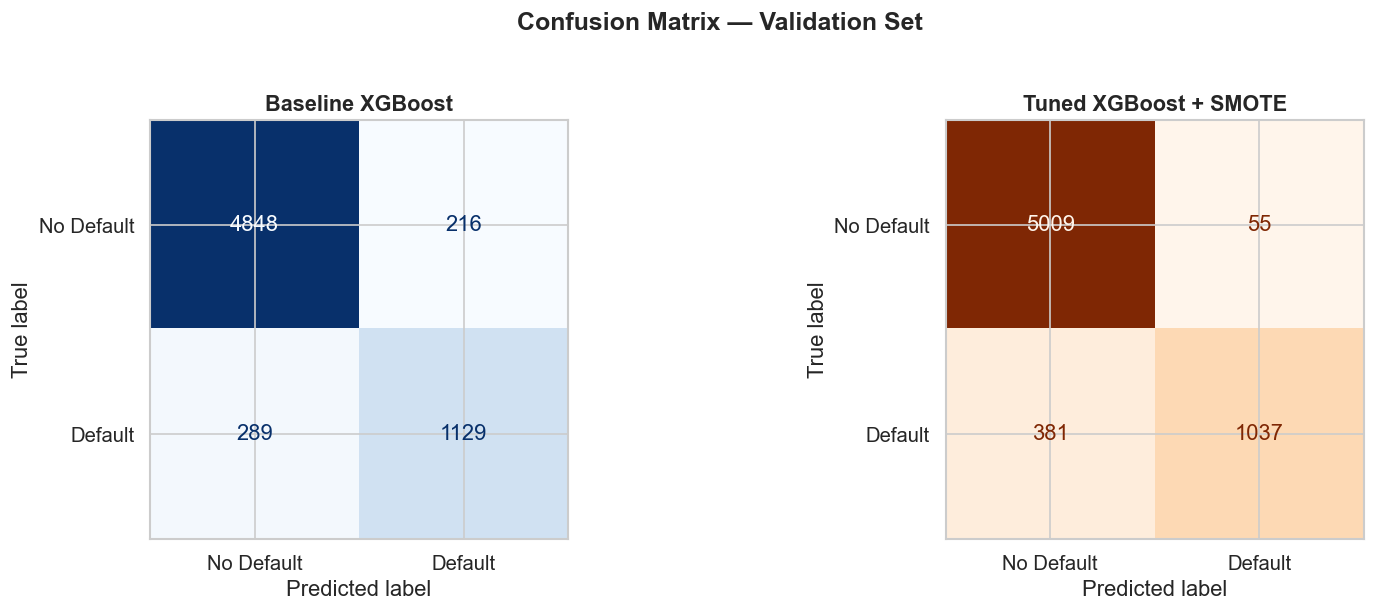

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Baseline
ConfusionMatrixDisplay.from_predictions(
    y_val, y_val_pred_baseline,
    display_labels=['No Default', 'Default'],
    cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title('Baseline XGBoost', fontsize=13, fontweight='bold')

# Tuned + SMOTE
ConfusionMatrixDisplay.from_predictions(
    y_val, y_val_pred,
    display_labels=['No Default', 'Default'],
    cmap='Oranges', ax=axes[1], colorbar=False
)
axes[1].set_title('Tuned XGBoost + SMOTE', fontsize=13, fontweight='bold')

plt.suptitle('Confusion Matrix — Validation Set', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Analysis
Compare the two confusion matrices above. The tuned model with SMOTE should show improved recall on the Default class (fewer false negatives), which is critical in credit risk — missing a potential defaulter is more costly than a false alarm.

---
## 11 · ROC Curve & Precision-Recall Curve

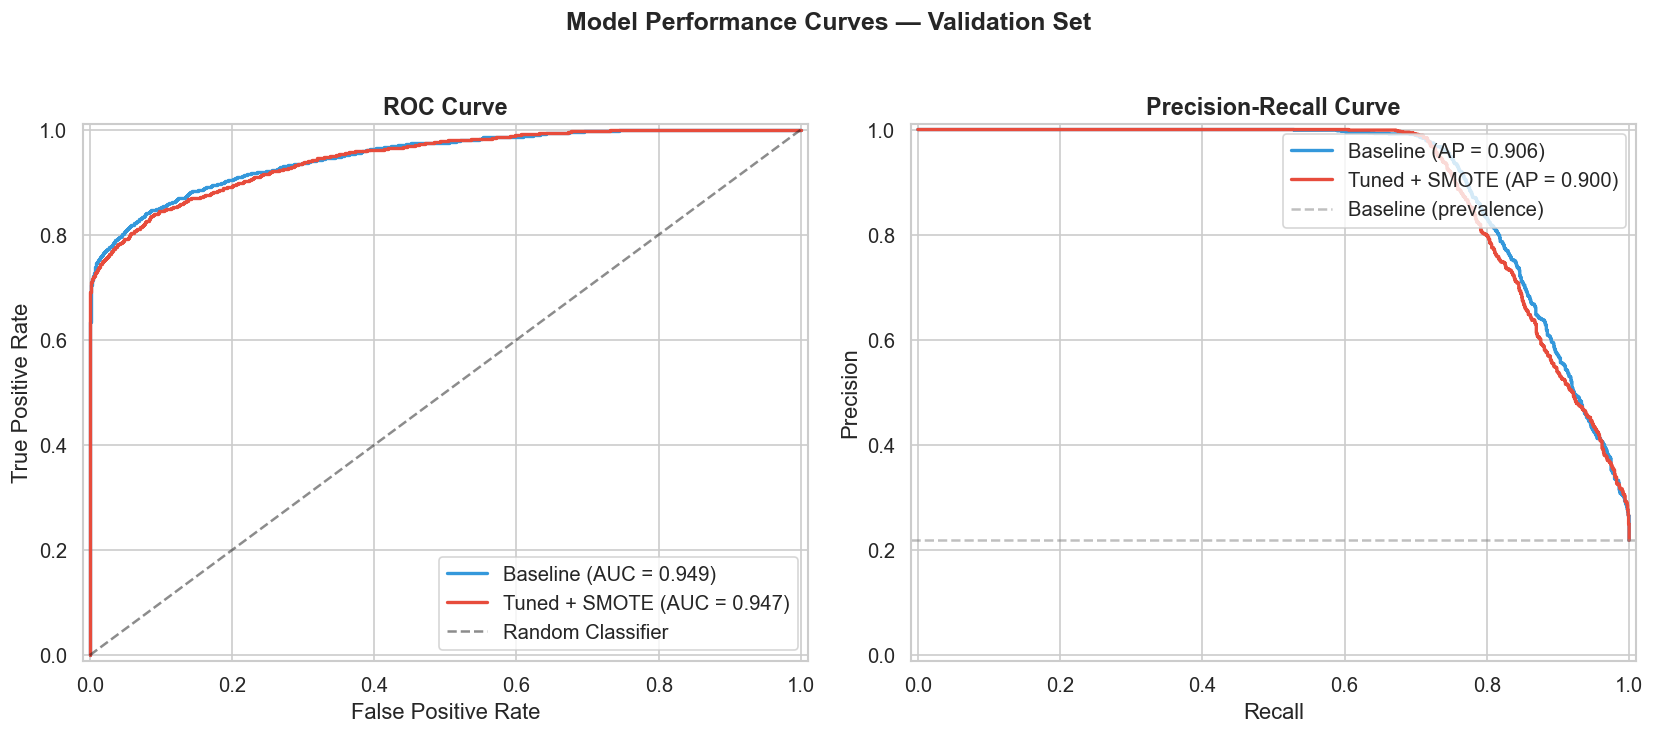

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ---- ROC Curve ----
fpr_base, tpr_base, _ = roc_curve(y_val, y_val_proba_baseline)
fpr_tuned, tpr_tuned, _ = roc_curve(y_val, y_val_proba)

axes[0].plot(fpr_base, tpr_base, color='#3498db', linewidth=2,
             label=f'Baseline (AUC = {roc_auc_score(y_val, y_val_proba_baseline):.3f})')
axes[0].plot(fpr_tuned, tpr_tuned, color='#e74c3c', linewidth=2,
             label=f'Tuned + SMOTE (AUC = {roc_auc_score(y_val, y_val_proba):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Classifier')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve', fontsize=14, fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].set_xlim([-0.01, 1.01])
axes[0].set_ylim([-0.01, 1.01])

# ---- Precision-Recall Curve ----
prec_base, rec_base, _ = precision_recall_curve(y_val, y_val_proba_baseline)
prec_tuned, rec_tuned, _ = precision_recall_curve(y_val, y_val_proba)

axes[1].plot(rec_base, prec_base, color='#3498db', linewidth=2,
             label=f'Baseline (AP = {average_precision_score(y_val, y_val_proba_baseline):.3f})')
axes[1].plot(rec_tuned, prec_tuned, color='#e74c3c', linewidth=2,
             label=f'Tuned + SMOTE (AP = {average_precision_score(y_val, y_val_proba):.3f})')
axes[1].axhline(y=y_val.mean(), color='grey', linestyle='--', alpha=0.5, label='Baseline (prevalence)')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve', fontsize=14, fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].set_xlim([-0.01, 1.01])
axes[1].set_ylim([-0.01, 1.01])

plt.suptitle('Model Performance Curves — Validation Set', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Analysis
- **ROC-AUC** measures the model's ability to discriminate between classes across all thresholds. A value significantly above 0.5 (random) indicates strong discriminative power.
- **PR-AUC** (Average Precision) is more informative than ROC-AUC for imbalanced datasets because it focuses on the minority class performance.
- Both curves should show the tuned model performing at least comparably to the baseline.

---
## 12 · Final Evaluation on Test Set
The test set has been held out until now. This gives us an unbiased estimate of real-world performance.

In [19]:
y_test_pred = final_model.predict(X_test_scaled)
y_test_proba = final_model.predict_proba(X_test_scaled)[:, 1]

print('=' * 55)
print('  FINAL EVALUATION — TEST SET (Tuned XGBoost + SMOTE)')
print('=' * 55)
print(classification_report(y_test, y_test_pred, target_names=['No Default', 'Default']))
print(f'Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}')
print(f'F1-Score:  {f1_score(y_test, y_test_pred):.4f}')
print(f'ROC-AUC:   {roc_auc_score(y_test, y_test_proba):.4f}')
print(f'PR-AUC:    {average_precision_score(y_test, y_test_proba):.4f}')

  FINAL EVALUATION — TEST SET (Tuned XGBoost + SMOTE)
              precision    recall  f1-score   support

  No Default       0.93      0.99      0.96      5065
     Default       0.95      0.75      0.84      1417

    accuracy                           0.94      6482
   macro avg       0.94      0.87      0.90      6482
weighted avg       0.94      0.94      0.93      6482

Accuracy:  0.9364
F1-Score:  0.8372
ROC-AUC:   0.9446
PR-AUC:    0.9006


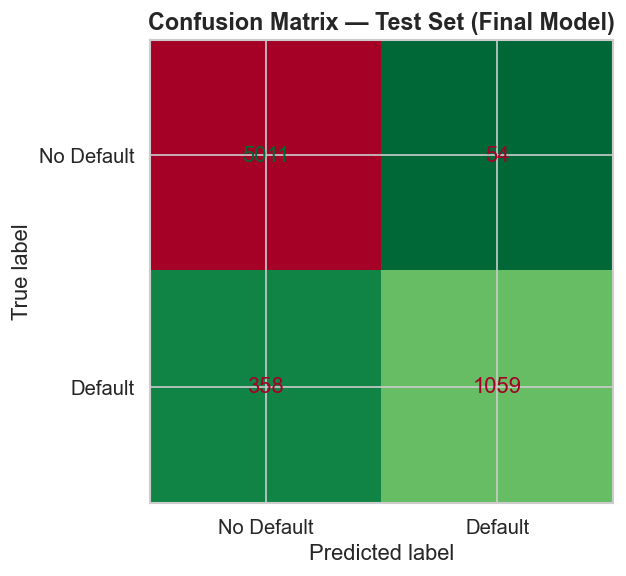

In [20]:
# Test set confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=['No Default', 'Default'],
    cmap='RdYlGn_r', ax=ax, colorbar=False
)
ax.set_title('Confusion Matrix — Test Set (Final Model)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Analysis
The test set results give us the unbiased, real-world performance estimate. If the test metrics are close to validation metrics, the model generalizes well and is not overfitting.

---
## 13 · Feature Importance Analysis

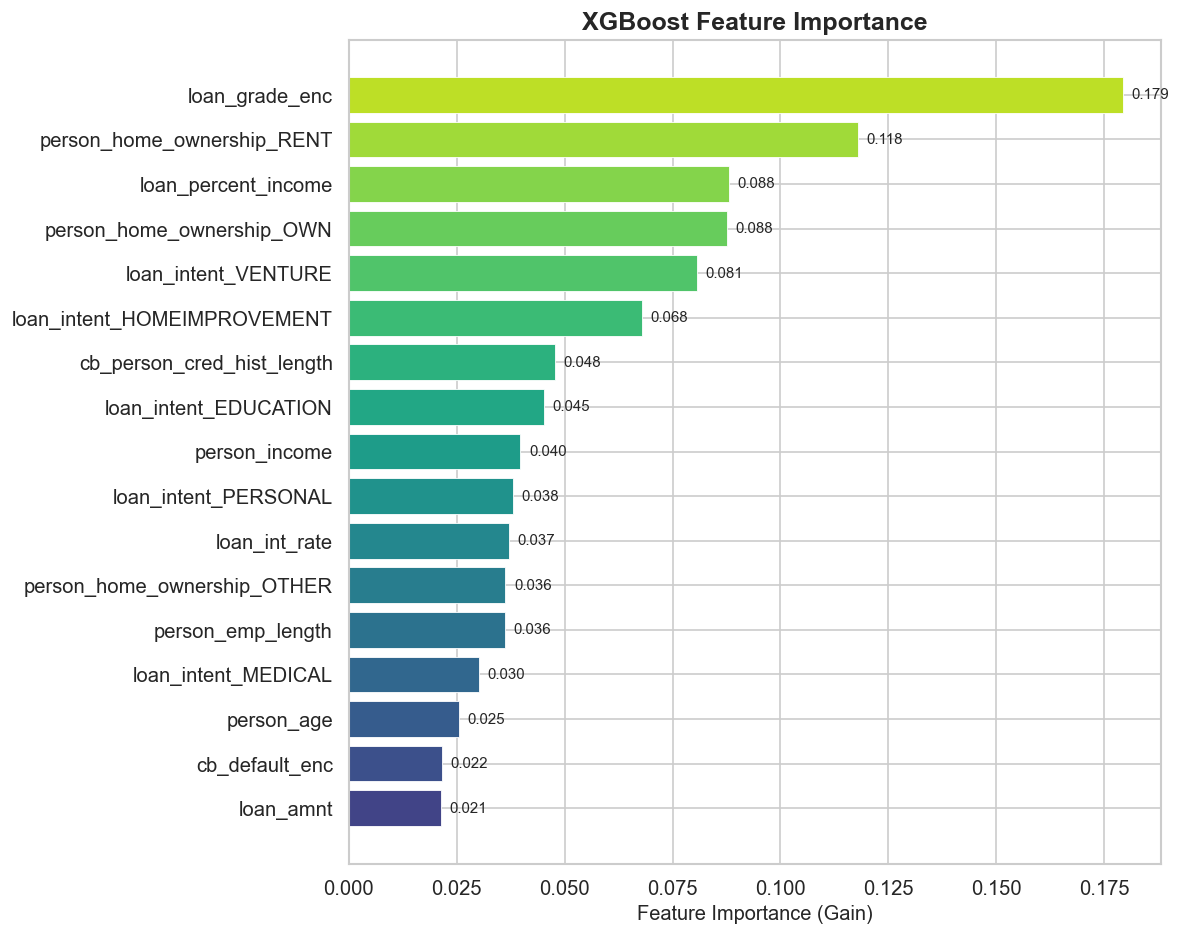


Top 5 most important features:
                   Feature  Importance
       loan_intent_VENTURE    0.080673
 person_home_ownership_OWN    0.087564
       loan_percent_income    0.087995
person_home_ownership_RENT    0.117863
            loan_grade_enc    0.179235


In [21]:
importance_df = pd.DataFrame({
    'Feature': FEATURE_NAMES,
    'Importance': final_model.feature_importances_
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))

colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(importance_df)))
ax.barh(importance_df['Feature'], importance_df['Importance'], color=colors, edgecolor='white', linewidth=0.5)
ax.set_xlabel('Feature Importance (Gain)', fontsize=12)
ax.set_title('XGBoost Feature Importance', fontsize=15, fontweight='bold')

# Add value labels
for i, (val, name) in enumerate(zip(importance_df['Importance'], importance_df['Feature'])):
    ax.text(val + 0.002, i, f'{val:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print('\nTop 5 most important features:')
print(importance_df.tail(5).to_string(index=False))

### Analysis
Feature importance reveals which variables drive the model's predictions most. In credit risk:
- **Loan-level features** (e.g., `loan_percent_income`, `loan_int_rate`, `loan_grade_enc`) are typically the strongest predictors.
- **Credit history** (`cb_person_cred_hist_length`, `cb_default_enc`) captures past borrower behavior.
- **Demographic features** (`person_age`, `person_income`) provide contextual information.

These insights help domain experts validate whether the model relies on sensible, non-discriminatory signals.

---
## 14 · Training History — Log-Loss Curves

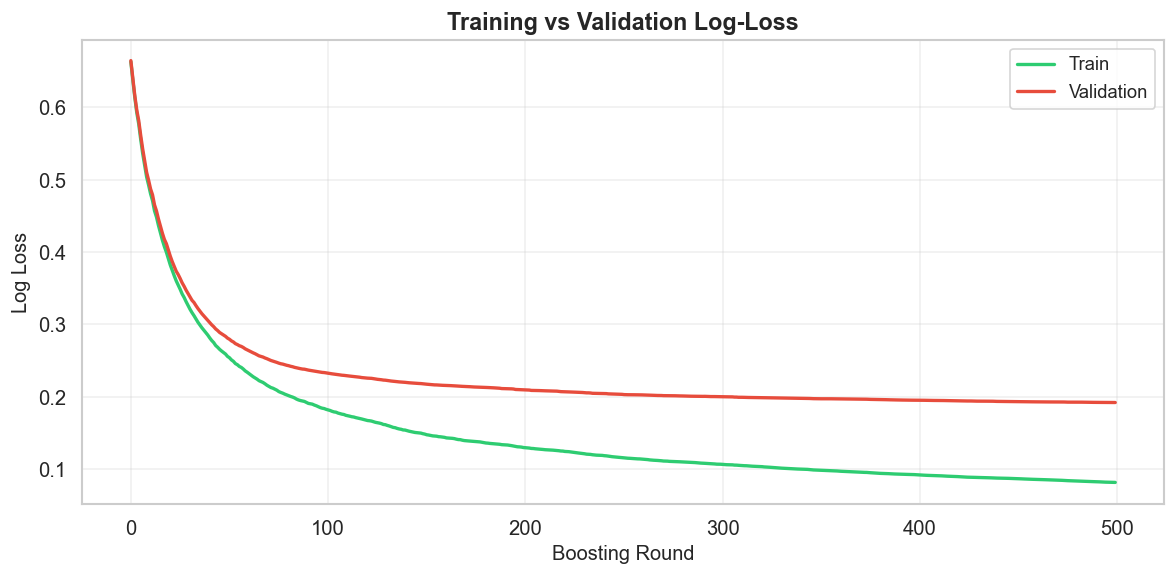

Final Train Log-Loss:      0.0817
Final Validation Log-Loss: 0.1921


In [22]:
results = final_model.evals_result()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(results['validation_0']['logloss'], label='Train', color='#2ecc71', linewidth=2)
ax.plot(results['validation_1']['logloss'], label='Validation', color='#e74c3c', linewidth=2)
ax.set_xlabel('Boosting Round', fontsize=12)
ax.set_ylabel('Log Loss', fontsize=12)
ax.set_title('Training vs Validation Log-Loss', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Final Train Log-Loss:      {results["validation_0"]["logloss"][-1]:.4f}')
print(f'Final Validation Log-Loss: {results["validation_1"]["logloss"][-1]:.4f}')

### Analysis
The log-loss curves show the training progression:
- If both curves converge and stay close, the model generalizes well.
- A widening gap (train decreasing while validation plateaus/increases) indicates overfitting — in which case, early stopping or stronger regularization would be needed.

---
## 15 · Save Model Artifacts

In [23]:
MODEL_DIR = '../ml_service'
os.makedirs(MODEL_DIR, exist_ok=True)

# Save the XGBoost model
model_path = os.path.join(MODEL_DIR, 'xgboost_credit_risk_model.joblib')
joblib.dump(final_model, model_path)
print(f'Model saved to: {model_path}')

# Save the scaler
scaler_path = os.path.join(MODEL_DIR, 'scaler.joblib')
joblib.dump(scaler, scaler_path)
print(f'Scaler saved to: {scaler_path}')

# Save feature names for inference
features_path = os.path.join(MODEL_DIR, 'feature_names.joblib')
joblib.dump(FEATURE_NAMES, features_path)
print(f'Feature names saved to: {features_path}')

# Save model metadata
metadata = {
    'model_type': 'XGBClassifier',
    'best_params': best_params,
    'training_samples': len(X_train_smote),
    'n_features': len(FEATURE_NAMES),
    'feature_names': FEATURE_NAMES,
    'test_metrics': {
        'accuracy': float(accuracy_score(y_test, y_test_pred)),
        'f1_score': float(f1_score(y_test, y_test_pred)),
        'roc_auc': float(roc_auc_score(y_test, y_test_proba)),
        'pr_auc': float(average_precision_score(y_test, y_test_proba))
    }
}
metadata_path = os.path.join(MODEL_DIR, 'model_metadata.joblib')
joblib.dump(metadata, metadata_path)
print(f'Metadata saved to: {metadata_path}')

# --- MLflow Logging: Run 2 (Tuned XGBoost + SMOTE) ---
with mlflow.start_run(run_name='02_Tuned_XGBoost_SMOTE'):
    # Log hyperparameters
    final_params = {
        'model_name': 'Tuned_XGBoost_SMOTE',
        'sampling': 'SMOTE',
        'scale_pos_weight': 1,
        'random_state': RANDOM_STATE,
        **{f'best_{k}': v for k, v in best_params.items()}
    }
    mlflow.log_params(final_params)

    # Log validation and test metrics
    mlflow.log_metrics({
        'val_accuracy': float(accuracy_score(y_val, y_val_pred)),
        'val_f1': float(f1_score(y_val, y_val_pred)),
        'val_roc_auc': float(roc_auc_score(y_val, y_val_proba)),
        'val_pr_auc': float(average_precision_score(y_val, y_val_proba)),
        'test_accuracy': float(accuracy_score(y_test, y_test_pred)),
        'test_f1': float(f1_score(y_test, y_test_pred)),
        'test_roc_auc': float(roc_auc_score(y_test, y_test_proba)),
        'test_pr_auc': float(average_precision_score(y_test, y_test_proba))
    })

    # Log model & local artifacts to MLflow
    mlflow.xgboost.log_model(final_model, artifact_path='final_model')
    mlflow.log_artifact(scaler_path, artifact_path='preprocessors')
    mlflow.log_artifact(features_path, artifact_path='preprocessors')
    mlflow.log_artifact(metadata_path, artifact_path='metadata')
    print('Tuned model, metrics & artifacts logged to MLflow.')

print(f'\nAll artifacts saved to: {os.path.abspath(MODEL_DIR)}')


2026/10/11 00:01:42 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Model saved to: ../ml_service\xgboost_credit_risk_model.joblib
Scaler saved to: ../ml_service\scaler.joblib
Feature names saved to: ../ml_service\feature_names.joblib
Metadata saved to: ../ml_service\model_metadata.joblib
Tuned model, metrics & artifacts logged to MLflow.

All artifacts saved to: c:\Users\User\OneDrive\Documents\Credit Risk Assessment & Loan Default Prediction System\ml_service


---
## 16 · Summary

### Data Analysis Key Findings
- The cleaned credit risk dataset contains **32,409 samples** with **17 features** and a binary target (`loan_status`).
- The dataset exhibits **class imbalance** with a ~3.6:1 ratio (78.1% non-default vs 21.9% default).
- Data was split into 60/20/20 train/validation/test sets with stratification to preserve class distribution.
- Feature scaling was applied using `StandardScaler` fitted exclusively on training data.

### Model Training & Evaluation
- A **baseline XGBoost** model was trained with `scale_pos_weight` to handle imbalance.
- **Hyperparameter tuning** via `RandomizedSearchCV` (50 iterations, 5-fold stratified CV, optimizing F1) identified optimal parameters.
- **SMOTE** was applied to the training set to synthetically balance classes before training the final model.
- The final model was evaluated on a **held-out test set** to provide an unbiased performance estimate.
- Feature importance analysis revealed the key drivers of default prediction.

### Insights & Next Steps
- **Feature importance** should be validated by domain experts to ensure the model doesn't rely on potentially discriminatory or proxy variables.
- Consider **threshold tuning** on the probability output to optimize for the specific business cost structure (cost of missed default vs. false alarm).
- The saved model artifacts (`ml_service/`) are ready for integration into a prediction API or dashboard.

---
## 11 · View Experiment Results in MLflow UI

To view, track, and compare all trained models interactively:

1. Open a terminal / command prompt in the project root directory.
2. Run the following command:
   ```bash
   mlflow ui
   ```
3. Open your browser and navigate to: **[http://localhost:5000](http://localhost:5000)**

You can compare `01_Baseline_XGBoost` vs `02_Tuned_XGBoost_SMOTE`, view metrics like ROC-AUC and F1-Score side by side, and inspect artifacts directly from the dashboard.
